# Gaze estimation pipeline

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/paragon0730/gaze_estimation/blob/main/pipeline.ipynb)

교재 7장 SimpleConvNet을 바꿔서 gaze 회귀용 CNN을 만들고 leave-one-person-out으로 평가해봄.

In [1]:
def is_colab():
    try:
        import google.colab  # noqa
        return True
    except ImportError:
        return False

if is_colab():
    !git clone https://github.com/paragon0730/gaze_estimation.git
    %cd gaze_estimation
    !pip -q install opencv-python scipy
    !apt-get -qq install -y fonts-nanum > /dev/null
    !python -m preprocess.mpii

In [2]:
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common.util import smooth_curve
from gaze import viz
from gaze.data import PERSONS, Standardizer, load_all, split_fold, stack
from gaze.experiment import CONFIG, make_set, run_fold
from gaze.metrics import angular_error
from gaze.model import GazeLeNet
from gaze.trainer import evaluate

viz.setup()
pd.set_option("display.precision", 2)

## 1. 데이터 나누기

- test: 1명 (3000개)
- val: test 다음 번호 1명 (epoch 고를 때만 사용)
- train: 나머지 13명
- 정규화 mean/std는 train 13명으로만 계산

In [3]:
data = load_all()
TEST = "p00"
train_p, val_p, test_p = split_fold(TEST)
print("train:", train_p, "\nval:", val_p, "\ntest:", test_p)

tr = stack(data, train_p)
std = Standardizer().fit(*tr)
train_set = make_set(std, *tr)
val_set = make_set(std, *stack(data, val_p))
test_set = make_set(std, *data[test_p])
print({k: v.shape for k, v in train_set.items()})
print(f"image mean/std {std.eye_mean:.3f}/{std.eye_std:.3f}, gaze mean {np.degrees(std.gaze_mean).round(2)}°, "
      f"gaze std {np.degrees(std.gaze_std).round(2)}°")

loaded cache data/mpiigaze_eye.npz: 45000 samples
train: ['p02', 'p03', 'p04', 'p05', 'p06', 'p07', 'p08', 'p09', 'p10', 'p11', 'p12', 'p13', 'p14'] 
val: ['p01'] 
test: p00


{'x': (39000, 1, 36, 60), 'head': (39000, 2), 't': (39000, 2), 'gaze': (39000, 2)}
image mean/std 0.507/0.290, gaze mean [ 0.07 -8.78]°, gaze std [8.79 5.25]°


## 2. 모델

MPIIGaze 논문(Zhang et al., 2015)에 있는 LeNet 구조 사용. head pose는 마지막 affine 전에 붙임.

conv(20,5x5) - relu - pool - conv(50,5x5) - relu - pool - affine(500) - relu - concat(head pose) - affine(2) - MSE

In [4]:
net = GazeLeNet(conv_params=CONFIG["conv_params"], hidden_size=CONFIG["hidden_size"], seed=0)
x = train_set["x"][:4]
print(f"{'input':10s} {x.shape}")
for name, layer in net.layers.items():
    x = layer.forward(x)
    print(f"{name:10s} {x.shape}")
x = net.concat.forward(x, train_set["head"][:4]); print(f"{'Concat':10s} {x.shape}")
x = net.out_layer.forward(x); print(f"{'Affine2':10s} {x.shape}")

n_params = {k: v.size for k, v in net.params.items()}
print(n_params, "\n총 매개변수:", sum(n_params.values()))

input      (4, 1, 36, 60)
Conv1      (4, 20, 32, 56)
Relu1      (4, 20, 32, 56)
Pool1      (4, 20, 16, 28)
Conv2      (4, 50, 12, 24)
Relu2      (4, 50, 12, 24)
Pool2      (4, 50, 6, 12)
Affine1    (4, 500)
ReluFC     (4, 500)
Concat     (4, 502)
Affine2    (4, 2)
{'W1': 500, 'b1': 20, 'W2': 25000, 'b2': 50, 'W3': 1800000, 'b3': 500, 'W4': 1004, 'b4': 2} 
총 매개변수: 1827076


### gradient check

새로 만든 Concat, MSE loss 계층이 맞는지 수치 미분이랑 비교. 원래 크기로 하면 너무 느려서 작은 네트워크로 확인함.

In [5]:
small = GazeLeNet(input_dim=(1, 12, 16), conv_params=((3, 3), (4, 3)), hidden_size=6, seed=1, dtype=np.float64)
rng = np.random.default_rng(0)
xs, hs, ts = rng.standard_normal((4, 1, 12, 16)), rng.standard_normal((4, 2)), rng.standard_normal((4, 2))
_, grad_bp = small.gradient(xs, hs, ts)
grad_num = small.numerical_gradient(xs, hs, ts)
for k in grad_bp:
    print(f"{k}: {grad_bp[k].shape}  max |backprop - numerical| = {np.abs(grad_bp[k] - grad_num[k]).max():.2e}")

W1: (3, 1, 3, 3)  max |backprop - numerical| = 2.60e-12
b1: (3,)  max |backprop - numerical| = 1.79e-12
W2: (4, 3, 3, 3)  max |backprop - numerical| = 3.32e-12
b2: (4,)  max |backprop - numerical| = 5.70e-13
W3: (8, 6)  max |backprop - numerical| = 1.74e-12
b3: (6,)  max |backprop - numerical| = 1.39e-12
W4: (8, 2)  max |backprop - numerical| = 1.73e-12
b4: (2,)  max |backprop - numerical| = 2.67e-13


## 3. p00 fold 학습

모든 fold 같은 하이퍼파라미터 사용 (`gaze/experiment.py`). epoch마다 val 오차를 보고 제일 낮은 epoch의 weight를 씀.

학습된 weight(`results/params/p00.pkl`)가 있으면 불러오고 없으면 새로 학습함.

In [6]:
print(json.dumps(CONFIG))
param_path, hist_path = f"results/params/{TEST}.pkl", f"results/lopo/{TEST}.json"
if os.path.exists(param_path) and os.path.exists(hist_path):
    net = GazeLeNet(conv_params=CONFIG["conv_params"], hidden_size=CONFIG["hidden_size"], seed=0)
    net.load_params(param_path)
    result = json.load(open(hist_path))
    print("학습된 매개변수를 불러옴:", param_path)
else:
    result, net, _, _ = run_fold(data, TEST, return_model=True)
hist = result["history"]

{"conv_params": [[20, 5], [50, 5]], "hidden_size": 500, "dropout_ratio": 0.0, "use_head": true, "epochs": 10, "batch_size": 128, "optimizer": "adam", "lr": 0.0005, "lr_decay": 0.8, "seed": 0, "use_val": true}
학습된 매개변수를 불러옴: results/params/p00.pkl


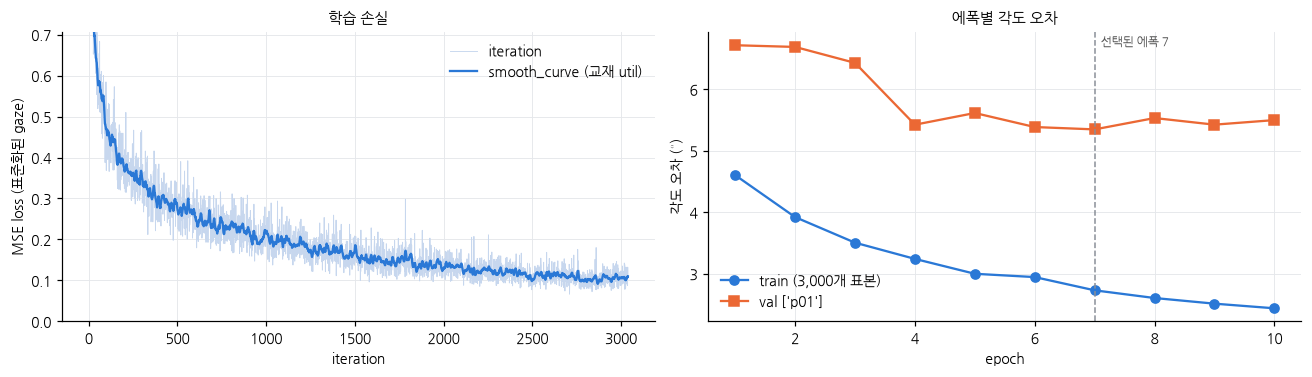

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
it = np.array(hist["iter_loss"])
axes[0].plot(it, color="#c7d7ee", lw=0.6, label="iteration")
axes[0].plot(smooth_curve(it), color=viz.BLUE, lw=1.5, label="smooth_curve (교재 util)")
axes[0].set(ylim=(0, np.percentile(it, 99)), xlabel="iteration", ylabel="MSE loss (표준화된 gaze)", title="학습 손실")
axes[0].legend(frameon=False)

ep = np.arange(1, len(hist["train_err"]) + 1)
axes[1].plot(ep, hist["train_err"], "o-", color=viz.BLUE, label="train (3,000개 표본)")
axes[1].plot(ep, hist["val_err"], "s-", color=viz.ORANGE, label=f"val {result['val']}")
axes[1].axvline(hist["best_epoch"], color=viz.GRAY, ls="--", lw=1)
axes[1].annotate(f"선택된 에폭 {hist['best_epoch']}", (hist["best_epoch"], max(hist["val_err"])),
                 xytext=(4, 0), textcoords="offset points", fontsize=8, color="#555")
axes[1].set(xlabel="epoch", ylabel="각도 오차 (°)", title="에폭별 각도 오차")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## 4. 평가 (test = p00)

In [8]:
test_err, pred = evaluate(net, std, test_set["x"], test_set["head"], test_set["gaze"])
gt = test_set["gaze"]
err = angular_error(pred, gt)
mean_err = angular_error(np.broadcast_to(tr[2].mean(0), gt.shape), gt).mean()
print(f"[{TEST}] GazeLeNet 평균 {test_err:.2f}°, 중앙값 {np.median(err):.2f}°")
print(f"[{TEST}] 평균 gaze 예측 {mean_err:.2f}°, ridge 회귀(README) 5.31°")

[p00] GazeLeNet 평균 5.09°, 중앙값 4.83°
[p00] 평균 gaze 예측 8.42°, ridge 회귀(README) 5.31°


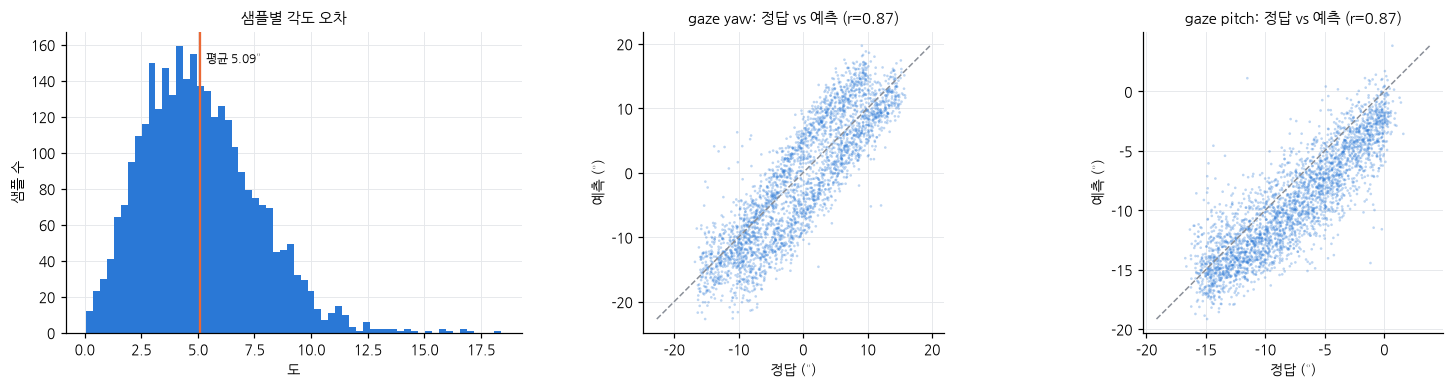

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(err, bins=60, color=viz.BLUE)
axes[0].axvline(err.mean(), color=viz.ORANGE, lw=1.5)
axes[0].annotate(f"평균 {err.mean():.2f}°", (err.mean(), axes[0].get_ylim()[1] * 0.9), xytext=(4, 0),
                 textcoords="offset points", fontsize=8)
axes[0].set(title="샘플별 각도 오차", xlabel="도", ylabel="샘플 수")
for ax, k, name in zip(axes[1:], [0, 1], ["yaw", "pitch"]):
    g, p = np.degrees(gt[:, k]), np.degrees(pred[:, k])
    ax.scatter(g, p, s=3, alpha=0.3, color=viz.BLUE, edgecolors="none")
    lim = [min(g.min(), p.min()), max(g.max(), p.max())]
    ax.plot(lim, lim, color=viz.GRAY, lw=1, ls="--")
    r = np.corrcoef(g, p)[0, 1]
    ax.set(title=f"gaze {name}: 정답 vs 예측 (r={r:.2f})", xlabel="정답 (°)", ylabel="예측 (°)")
    ax.set_aspect("equal")
plt.tight_layout(); plt.show()

## 5. 오차 분석

평균 gaze에서 멀리 떨어진 샘플일수록 오차가 큰지, 왼눈/오른눈 차이가 있는지 확인.

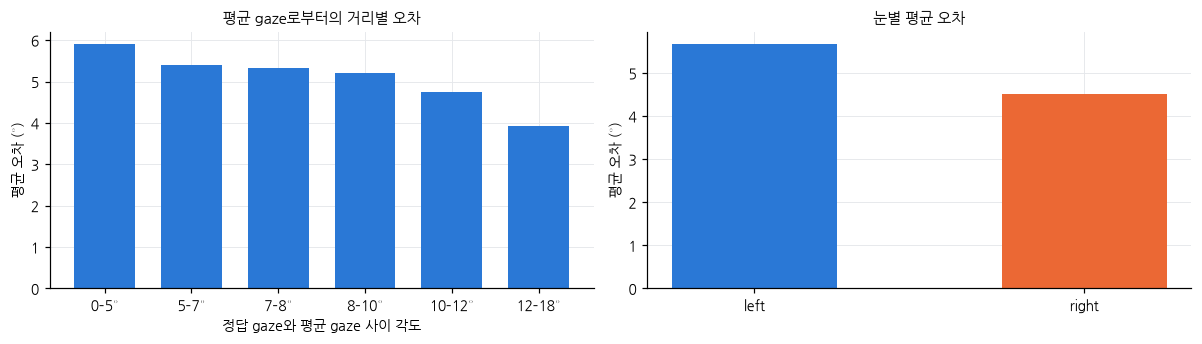

In [10]:
meta = pd.read_csv(f"data/EyeBased/MPIIGaze/Label/{TEST}.label", sep=" ")
dev = angular_error(np.broadcast_to(tr[2].mean(0), gt.shape), gt)  # 평균 gaze로부터 떨어진 정도
bins = np.quantile(dev, np.linspace(0, 1, 7))
which = np.clip(np.digitize(dev, bins[1:-1]), 0, 5)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].bar(range(6), [err[which == b].mean() for b in range(6)], color=viz.BLUE, width=0.7)
axes[0].set_xticks(range(6), [f"{bins[b]:.0f}–{bins[b+1]:.0f}°" for b in range(6)])
axes[0].set(title="평균 gaze로부터의 거리별 오차", xlabel="정답 gaze와 평균 gaze 사이 각도", ylabel="평균 오차 (°)")
eyes = meta["WhichEye"].values
axes[1].bar(["left", "right"], [err[eyes == "left"].mean(), err[eyes == "right"].mean()],
            color=[viz.BLUE, viz.ORANGE], width=0.5)
axes[1].set(title="눈별 평균 오차", ylabel="평균 오차 (°)")
plt.tight_layout(); plt.show()

잘 맞춘 것 / 많이 틀린 것 (초록: 정답, 주황: 예측)

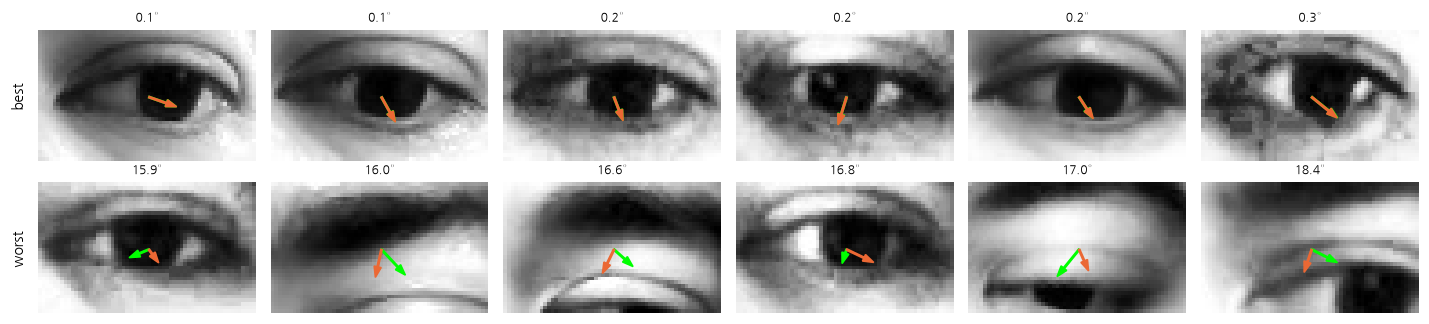

In [11]:
order = np.argsort(err)
fig, axes = plt.subplots(2, 6, figsize=(13, 3))
for row, idx in zip(axes, [order[:6], order[-6:]]):
    for ax, i in zip(row, idx):
        img = data[TEST][0][i] / 255.0
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        viz.draw_gaze(ax, img, gt[i], "lime")
        viz.draw_gaze(ax, img, pred[i], viz.ORANGE)
        ax.set_title(f"{err[i]:.1f}°", fontsize=8); ax.axis("off")
axes[0, 0].text(-8, 18, "best", rotation=90, va="center", fontsize=9)
axes[1, 0].text(-8, 18, "worst", rotation=90, va="center", fontsize=9)
plt.tight_layout(); plt.show()

## 6. 필터 시각화

conv1 필터 학습 전/후

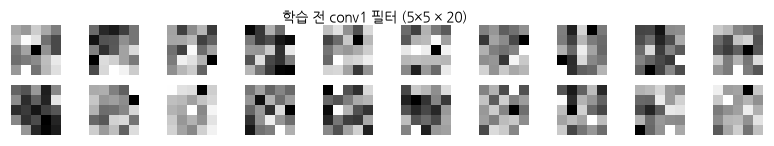

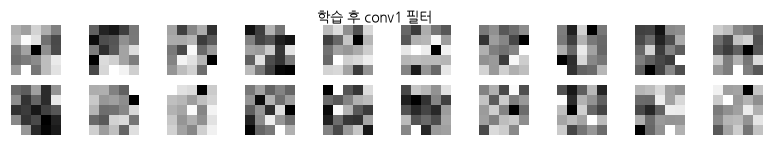

In [12]:
def show_filters(W, title):
    n = W.shape[0]
    fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(n * 0.45, 1.3))
    for ax, i in zip(axes.ravel(), range(n)):
        ax.imshow(W[i, 0], cmap="gray", interpolation="nearest"); ax.axis("off")
    for ax in axes.ravel()[n:]:
        ax.axis("off")
    fig.suptitle(title, fontsize=9); plt.show()

init = GazeLeNet(conv_params=CONFIG["conv_params"], hidden_size=CONFIG["hidden_size"], seed=CONFIG["seed"])
show_filters(init.params["W1"], "학습 전 conv1 필터 (5×5 × 20)")
show_filters(net.params["W1"], "학습 후 conv1 필터")

feature map (conv1, conv2 출력)

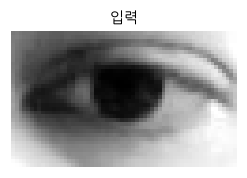

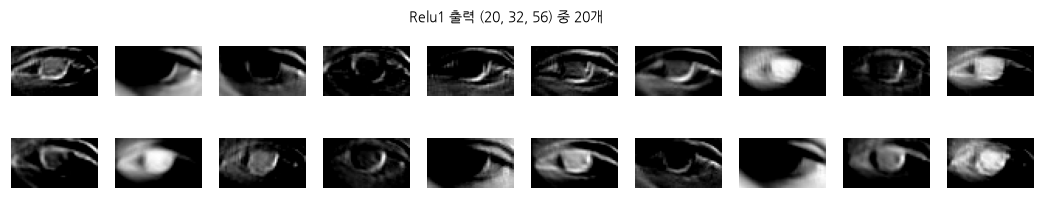

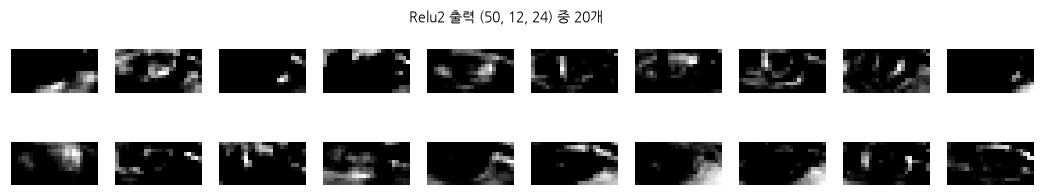

In [13]:
i = order[len(order) // 2]
x = test_set["x"][i:i + 1]
outs = {}
for name, layer in net.layers.items():
    x = layer.forward(x)
    if name in ("Relu1", "Relu2"):
        outs[name] = x[0]

fig = plt.figure(figsize=(12, 1.6))
ax = fig.add_subplot(1, 1, 1); ax.imshow(data[TEST][0][i], cmap="gray"); ax.axis("off"); ax.set_title("입력")
plt.show()
for name, n_show, ncol in [("Relu1", 20, 10), ("Relu2", 20, 10)]:
    fmap = outs[name]
    fig, axes = plt.subplots(n_show // ncol, ncol, figsize=(12, 1.0 * n_show // ncol))
    for ax, k in zip(axes.ravel(), range(n_show)):
        ax.imshow(fmap[k], cmap="gray"); ax.axis("off")
    fig.suptitle(f"{name} 출력 {fmap.shape} 중 {n_show}개", fontsize=9); plt.show()

## 7. 전체 15 fold 결과

`train_lopo.py`로 돌린 결과 (`results/lopo_results.csv`)

,p00,p01,p02,p03,p04,p05,p06,p07,p08,p09,p10,p11,p12,p13,p14,평균
cnn,5.09,6.73,6.52,6.11,6.66,5.74,6.53,6.99,6.52,7.81,7.26,5.70,5.68,6.95,5.75,6.40
ridge,5.31,7.76,6.55,8.05,6.40,7.35,7.59,7.97,7.89,8.51,6.93,6.63,7.07,7.85,7.20,7.27
mean_gaze,8.42,8.61,9.00,9.60,8.97,9.73,10.36,9.50,9.62,8.97,8.66,8.43,8.60,9.00,10.76,9.22
best_epoch,7.00,1.00,4.00,2.00,2.00,9.00,5.00,2.00,4.00,2.00,1.00,5.00,5.00,3.00,1.00,3.53


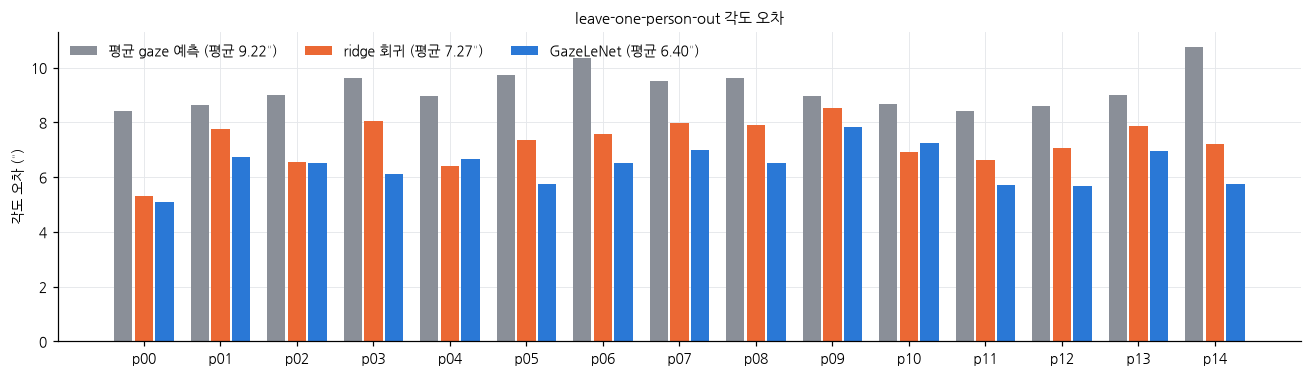

In [14]:
csv = "results/lopo_results.csv"
if os.path.exists(csv):
    res = pd.read_csv(csv).set_index("person")
    display(pd.concat([res, res.mean(numeric_only=True).to_frame("평균").T]).T)
    fig, ax = plt.subplots(figsize=(12, 3.5))
    xs = np.arange(len(res))
    w = 0.27
    for k, (col, name, color) in enumerate([("mean_gaze", "평균 gaze 예측", viz.GRAY),
                                            ("ridge", "ridge 회귀", viz.ORANGE),
                                            ("cnn", "GazeLeNet", viz.BLUE)]):
        ax.bar(xs + (k - 1) * w, res[col], width=w - 0.03, color=color,
               label=f"{name} (평균 {res[col].mean():.2f}°)")
    ax.set_xticks(xs, res.index)
    ax.set(ylabel="각도 오차 (°)", title="leave-one-person-out 각도 오차")
    ax.legend(frameon=False, ncol=3, loc="upper left")
    plt.tight_layout(); plt.show()
else:
    print("results/lopo_results.csv가 없음. python train_lopo.py 후 python train_lopo.py --summarize 실행")

## 정리

- 15 fold 평균 6.40°. ridge(7.27°), 평균 예측(9.22°)보다 낮음
- p04, p10은 ridge보다 조금 높게 나옴
- 논문에서 같은 구조로 6.3° 나왔다고 해서 비슷한 수준은 나온 듯 (전처리가 달라서 정확한 비교는 아님)
- train 오차는 계속 내려가는데 val은 몇 epoch 지나면 안 내려감 → 다른 사람한테 일반화하는 게 어려움
- 많이 틀린 샘플은 눈을 감았거나 눈이 잘렸거나 안경테가 걸친 경우가 많았음
- 해볼 만한 것: dropout, batch norm, weight decay, data augmentation